# **Introduction to AI Workshop: Example 02**
In this example, we will construct a neural network to **recognize handwritten digits**. The goal of this neural network will be to **classify** images of handwritten digits into 10 different **classes** (0 through 9).

First, we import the `TensorFlow` and `numpy` libraries.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

Next, we load the MNIST dataset, which has images of handwritten digits (from 0 to 9).

In [2]:
data = tf.keras.datasets.mnist

The images in the MNIST dataset are divided into two sets: a **training set** of images that we will use to train the neural network and a **test set** of previously unseen images that we will use to evaluate the performance of the neural network.

In [3]:
(x_train, y_train), (x_test, y_test) = data.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Let's explore the training set and the test set to get a better understanding of this data. **How many images are in the training set? How many images are in the test set? What is the size of each of these images?**

In [4]:
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


Let's also print one of the images in the training set and its corresponding **class label** to see what they look like. **Try changing the index of `x_train` and `y_train` to print other images.**

8
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38  48
   48  22   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0  62  97 198 243 254
  254 212  27   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  67 172 254 

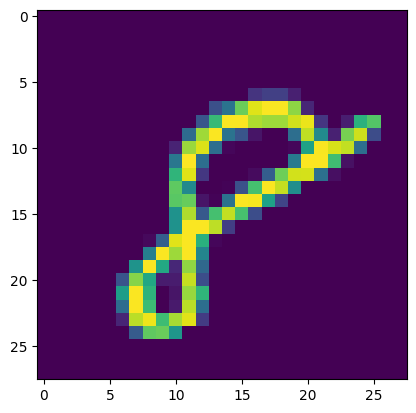

In [5]:
print(y_train[59999]) # class label
print(x_train[59999]) # image
plt.imshow(x_train[59999])

Notice that each image in `x_train` is represented by a 28x28 matrix filled with values between 0 and 255. **What do these values represent?**

When we are training a neural network, it's easier if all the values are between 0 and 1, so we **normalize** the values in `x_train` and `x_test`.

In [6]:
x_train = x_train / 255.0
x_test = x_test / 255.0

Let's now design our neural network with a sequence of **layers**. For each layer, we specify the number of **neurons** and an **activation function**.

First, we have the **input** (**Flatten**) layer, which "flattens" (i.e., reshapes) the data from a 3D array to a 2D array.

We follow this with a **hidden** (**Dense**) layer.

Finally, we have the **output** (**Dense**) layer. Notice that the number of neurons in this last layer should match the number of classes in the data.



In [7]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)), # input layer
  tf.keras.layers.Dense(128, activation=tf.nn.relu), # hidden layer
  tf.keras.layers.Dense(10, activation=tf.nn.softmax) # output layer
])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

We compile our neural network by specifying the loss function and the optimization algorithm, as well as a **metric** to evaluate the performance of the neural network. In this case, we use **accuracy** (that is, the fraction of images correctly classified) as the evaluation metric.

In [8]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

We then train our neural network to fit the training data.

In [9]:
model.fit(x_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9264 - loss: 0.2578
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9666 - loss: 0.1147
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9762 - loss: 0.0779
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9825 - loss: 0.0573
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9862 - loss: 0.0445


Once it's done training, notice the accuracy at the end of the final epoch. It should be around 98%, which means that 98% of the images in the training set were classified correctly.

**But how well does our neural network do with unseen images?** To find out, we try to classify the images in the test set.

In [10]:
predictions = model.predict(x_test)
print(predictions[0]) # output
print(np.around(predictions[0], 3)) # rounded output

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
[7.80642182e-08 3.04709435e-09 4.69637052e-06 2.66338902e-05
 7.38543168e-12 1.40571954e-08 1.10430226e-13 9.99965727e-01
 3.13758392e-07 2.52975246e-06]
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


In [11]:
print(y_test[0])

7


Notice that the output for each image is a list of numbers. **What do these numbers represent? What is the predicted class label for the first image in the test set? Was this image classified correctly?**

We can also evaluate the performance of our neural network on the test set.

In [12]:
model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9787 - loss: 0.0728


[0.07283484935760498, 0.9786999821662903]

The accuracy on the test set should be around 97%, which means that 97% of the images in the test set were classified correctly. This is still very good, but it's lower than the accuracy on the training set, which is expected. **But can we do any better?**